# 86 - Figura de exemplo do t-SNE

Objetivo: gerar uma figura ilustrativa do t-SNE para o referencial teorico do TCC (secao de visualizacao dos clusters).

Dados: conjunto `digits` do scikit-learn (1.797 imagens 8x8 de algarismos manuscritos, com rotulo de 0 a 9). Ele e usado apenas como exemplo didatico, pois seus rotulos conhecidos permitem ver se a projecao preserva os grupos. Nao ha relacao com os dados de notas fiscais.

Saida: `docs/overleaf/images/tsne-exemplo-digits.png`.

## Configuracoes

In [1]:
OUTPUT_PATH = "docs/overleaf/images/tsne-exemplo-digits.png"
RANDOM_STATE = 42
PERPLEXITY = 30
FIGURE_SIZE = (5, 4.2)
DPI = 200

## Funcoes

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE


def project_with_tsne(vectors, perplexity, random_state):
    """Projeta os vetores em duas dimensoes com t-SNE."""
    tsne = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=random_state)
    return tsne.fit_transform(vectors)


def plot_projection(projection, labels, figure_size):
    """Desenha a projecao colorida pelo rotulo e anota cada algarismo no ponto mediano do seu grupo."""
    figure, axis = plt.subplots(figsize=figure_size)
    scatter = axis.scatter(projection[:, 0], projection[:, 1], c=labels, cmap="tab10", s=6, alpha=0.8)
    for digit in range(10):
        center = np.median(projection[labels == digit], axis=0)
        axis.text(center[0], center[1], str(digit), fontsize=12, weight="bold",
                  ha="center", va="center", bbox=dict(boxstyle="circle", facecolor="white", alpha=0.8))
    axis.set_xticks([])
    axis.set_yticks([])
    figure.tight_layout()
    return figure

## Execucao

In [3]:
# Carregamento
repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
digits = load_digits()
print(f"Imagens: {digits.data.shape[0]}, dimensoes: {digits.data.shape[1]}")

Imagens: 1797, dimensoes: 64


In [4]:
# Projecao
projection = project_with_tsne(digits.data, PERPLEXITY, RANDOM_STATE)

Figura gravada em docs/overleaf/images/tsne-exemplo-digits.png


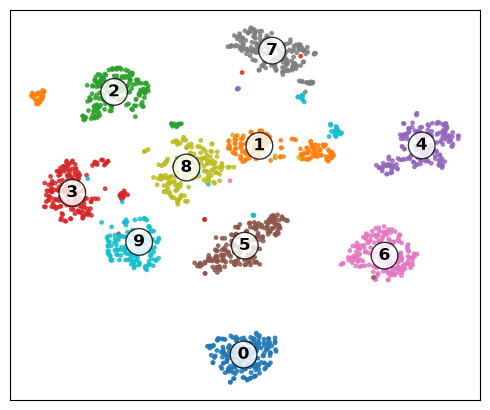

In [5]:
# Persistencia: grava a figura usada no TCC
figure = plot_projection(projection, digits.target, FIGURE_SIZE)
output_file = repo_root / OUTPUT_PATH
figure.savefig(output_file, dpi=DPI, bbox_inches="tight")
print(f"Figura gravada em {OUTPUT_PATH}")